# Bài tập 2 - Hồng Gấm

Môn 121036. Người phụ trách: **Hồng Gấm**.

Hoàn thành nội bộ: **18/11/2026**. Hạn nộp: **20/11/2026**.

Bộ khung chưa có thuật toán hoặc kết quả thực nghiệm. Đọc `README.md`, đề Bài tập 2 và bảng phân công của nhóm.

## 0. Chuẩn bị môi trường

Cell bên dưới do Codex tạo để import thư viện và xác định đường dẫn, ngoài phần cài đặt thuật toán. Các cell cài đặt được để trống.

**Khai báo AI cho cell chuẩn bị**

- Công cụ: Codex (OpenAI).
- Mục đích: tạo bộ khung thư mục, notebook và đường dẫn dùng chung.
- Prompt nguyên văn:

> giờ bạn tạo cái sườn giúp tôi [https://github.com/NguyenTanHiep07/xla-121036](https://github.com/NguyenTanHiep07/xla-121036) làm tiếp trong này cho dễ nha tạo mấy thư mục mấy cũ ko liên quan á bỏ qua

In [200]:
from pathlib import Path
import math
import time

import numpy as np
import matplotlib.pyplot as plt

# Chuẩn bị đường dẫn, không cài đặt thuật toán.
thu_muc_chay = Path.cwd().resolve()
thu_muc_tim = (
    thu_muc_chay,
    thu_muc_chay / "bai_tap_2",
    thu_muc_chay.parent,
)
BT2_DIR = next(
    (p for p in thu_muc_tim if (p / "bt2_nhom.ipynb").is_file()),
    None,
)
if BT2_DIR is None:
    raise FileNotFoundError(
        "Chọn thư mục chạy là gốc repo, bai_tap_2 hoặc bai_tap_2/lam_viec."
    )
IMAGES_DIR = BT2_DIR.parent / "images"
print("Bài tập 2:", BT2_DIR)
print("Ảnh dùng chung:", IMAGES_DIR)


Bài tập 2: C:\Users\ad\OneDrive\XLA\xla-121036-main\xla-121036-main\bai_tap_2
Ảnh dùng chung: C:\Users\ad\OneDrive\XLA\xla-121036-main\xla-121036-main\images


## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `gaussian_blur(img, sigma)`

Làm mờ Gauss; được phép dùng scipy.ndimage.gaussian_filter.

In [201]:

def gaussian_blur(img, sigma):
    img = np.asarray(img, dtype=np.float64)

    if sigma <= 0:
        return img.copy()

    radius = int(np.ceil(3 * sigma))
    x = np.arange(-radius, radius + 1, dtype=np.float64)

    kernel_1d = np.exp(-(x ** 2) / (2 * sigma ** 2))
    kernel_1d /= kernel_1d.sum()

    kernel = np.outer(kernel_1d, kernel_1d)

    padded = np.pad(img, radius, mode="reflect")
    result = np.zeros_like(img)

    for i in range(kernel.shape[0]):
        for j in range(kernel.shape[1]):
            result += kernel[i, j] * padded[
                i:i + img.shape[0],
                j:j + img.shape[1]
            ]

    return result


### `structure_tensor(img, sigma_i, sigma_d)`

Trả (Mxx, Mxy, Myy), mỗi mảng cùng kích thước ảnh; có hệ số sigma_d**2 theo đề.

In [202]:

def structure_tensor(img, sigma_i, sigma_d):
    img = np.asarray(img, dtype=np.float64)

    blurred = gaussian_blur(img, sigma_d)

    Iy, Ix = np.gradient(blurred)

    factor = sigma_d ** 2

    Mxx = factor * gaussian_blur(Ix ** 2, sigma_i)
    Mxy = factor * gaussian_blur(Ix * Iy, sigma_i)
    Myy = factor * gaussian_blur(Iy ** 2, sigma_i)

    return Mxx, Mxy, Myy


### `harris_response(img, sigma_i, sigma_d, k=0.04)`

Trả đáp ứng R dạng mảng float cùng kích thước ảnh.

In [203]:

def harris_response(img, sigma_i, sigma_d, k=0.04):
    Mxx, Mxy, Myy = structure_tensor(
        img, sigma_i, sigma_d
    )

    det = Mxx * Myy - Mxy ** 2
    trace = Mxx + Myy

    R = det - k * trace ** 2

    return R


### `nms_2d(response, window=3)`

Trả mảng bool đánh dấu cực đại địa phương.

In [204]:

def nms_2d(response, window=3):
    response = np.asarray(response, dtype=np.float64)

    if window < 1 or window % 2 == 0:
        raise ValueError("window phải là số nguyên dương lẻ")

    radius = window // 2

    padded = np.pad(
        response,
        radius,
        mode="constant",
        constant_values=-np.inf
    )

    local_max = np.full_like(response, -np.inf)

    for i in range(window):
        for j in range(window):
            region = padded[
                i:i + response.shape[0],
                j:j + response.shape[1]
            ]
            local_max = np.maximum(local_max, region)

    return (response == local_max) & np.isfinite(response)


### `harris_classic(img, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01)`

Trả mảng (N, 3): (row, col, response), giảm dần theo response.

In [205]:

def harris_classic(
    img,
    sigma_i=2.0,
    sigma_d=1.4,
    k=0.04,
    thresh_rel=0.01
):
    R = harris_response(img, sigma_i, sigma_d, k)

    max_response = np.max(R)

    if max_response <= 0:
        return np.empty((0, 3), dtype=np.float64)

    mask = nms_2d(R, window=3)
    mask &= R > thresh_rel * max_response
    mask &= R > 0

    rows, cols = np.where(mask)
    responses = R[rows, cols]

    points = np.column_stack((rows, cols, responses))

    order = np.argsort(points[:, 2])[::-1]

    return points[order]


### `repeatability(pts_a, pts_b, transform, img_shape, eps=3.0)`

Tỉ lệ trong [0, 1]. transform ánh xạ (row, col) của A sang B; chỉ tính điểm chiếu còn trong ảnh B.

In [206]:

def repeatability(pts_a, pts_b, transform, img_shape, eps=3.0):
    pts_a = np.asarray(pts_a, dtype=np.float64)
    pts_b = np.asarray(pts_b, dtype=np.float64)

    if pts_a.size == 0 or pts_b.size == 0:
        return 0.0

    coords_a = pts_a.reshape(-1, pts_a.shape[-1])[:, :2]
    coords_b = pts_b.reshape(-1, pts_b.shape[-1])[:, :2]

    if callable(transform):
        projected = np.asarray(
            transform(coords_a),
            dtype=np.float64
        ).reshape(-1, 2)
    else:
        H = np.asarray(transform, dtype=np.float64)

        if H.shape != (3, 3):
            raise ValueError("transform phải là ma trận 3x3")

        xy1 = np.column_stack((
            coords_a[:, 1],
            coords_a[:, 0],
            np.ones(len(coords_a))
        ))

        mapped = (H @ xy1.T).T

        projected = np.full(
            (len(coords_a), 2),
            np.nan,
            dtype=np.float64
        )

        valid_w = (
            np.isfinite(mapped[:, 2]) &
            (np.abs(mapped[:, 2]) > 1e-12)
        )

        projected[valid_w, 0] = (
            mapped[valid_w, 1] / mapped[valid_w, 2]
        )

        projected[valid_w, 1] = (
            mapped[valid_w, 0] / mapped[valid_w, 2]
        )

    h, w = img_shape[:2]

    valid = (
        np.isfinite(projected).all(axis=1) &
        (projected[:, 0] >= 0) &
        (projected[:, 0] < h) &
        (projected[:, 1] >= 0) &
        (projected[:, 1] < w)
    )

    projected = projected[valid]

    coords_b = coords_b[
        np.isfinite(coords_b).all(axis=1)
    ]

    if len(projected) == 0 or len(coords_b) == 0:
        return 0.0

    distances = np.linalg.norm(
        projected[:, None, :] -
        coords_b[None, :, :],
        axis=2
    )

    matches = np.min(distances, axis=1) <= eps

    return float(np.mean(matches))


In [207]:

# tu kiem tra 6 ham harris

img = np.zeros((64, 64), dtype=np.float64)
img[16:48, 16:48] = 255


# gaussian_blur

sigma = 1.4
blur = gaussian_blur(img, sigma)

print("\ngaussian_blur")
print("sigma:", sigma)
print("kich thuoc anh goc:", img.shape)
print("kich thuoc anh sau lam mo:", blur.shape)
print("gia tri min:", round(float(blur.min()), 4))
print("gia tri max:", round(float(blur.max()), 4))
print("gia tri trung binh:", round(float(blur.mean()), 4))
print("tong gia tri pixel:", round(float(blur.sum()), 4))


# structure_tensor

sigma_i = 2.0
sigma_d = 1.4

Mxx, Mxy, Myy = structure_tensor(img, sigma_i, sigma_d)

print("\nstructure_tensor")
print("sigma_i:", sigma_i)
print("sigma_d:", sigma_d)
print("he so sigma_d^2:", sigma_d ** 2)
print("kich thuoc Mxx:", Mxx.shape)
print("kich thuoc Mxy:", Mxy.shape)
print("kich thuoc Myy:", Myy.shape)
print("Mxx min:", round(float(Mxx.min()), 4))
print("Mxx max:", round(float(Mxx.max()), 4))
print("Mxy min:", round(float(Mxy.min()), 4))
print("Mxy max:", round(float(Mxy.max()), 4))
print("Myy min:", round(float(Myy.min()), 4))
print("Myy max:", round(float(Myy.max()), 4))


# harris_response

k = 0.04
R = harris_response(img, sigma_i, sigma_d, k)

print("\nharris_response")
print("k:", k)
print("kich thuoc response:", R.shape)
print("response min:", round(float(R.min()), 4))
print("response max:", round(float(R.max()), 4))
print("response trung binh:", round(float(R.mean()), 4))
print("so pixel response duong:", int(np.sum(R > 0)))
print("so pixel response am:", int(np.sum(R < 0)))


# nms_2d

window = 3

test_R = np.array([
    [0, 0, 0],
    [0, 5, 0],
    [0, 0, 0]
], dtype=np.float64)

mask = nms_2d(test_R, window)

print("\nnms_2d")
print("window:", window)
print("kich thuoc response:", test_R.shape)
print("kich thuoc mask:", mask.shape)
print("kieu du lieu mask:", mask.dtype)
print("so cuc dai cuc bo:", int(mask.sum()))
print("toa do cuc dai:", np.argwhere(mask).tolist())


# harris_classic

pts = harris_classic(
    img,
    sigma_i=2.0,
    sigma_d=1.4,
    k=0.04,
    thresh_rel=0.01
)

print("\nharris_classic")
print("sigma_i:", 2.0)
print("sigma_d:", 1.4)
print("k:", 0.04)
print("thresh_rel:", 0.01)
print("so diem goc phat hien:", len(pts))
print("kich thuoc mang diem:", pts.shape)
print("dinh dang: (row, col, response)")
print("5 diem co response cao nhat:")
print(np.round(pts[:5], 4))


# repeatability

pts_a = np.array([
    [10, 10, 1],
    [20, 20, 1],
    [30, 30, 1]
], dtype=np.float64)

pts_b = np.array([
    [10, 10, 1],
    [20, 20, 1],
    [40, 40, 1]
], dtype=np.float64)

H = np.eye(3)
eps = 3.0

score = repeatability(
    pts_a,
    pts_b,
    H,
    (64, 64),
    eps=eps
)

pts_outside = np.array([
    [10, 10, 1],
    [20, 20, 1],
    [100, 100, 1]
], dtype=np.float64)

score_outside = repeatability(
    pts_outside,
    pts_b,
    H,
    (64, 64),
    eps=eps
)

score_empty = repeatability(
    np.empty((0, 3)),
    pts_b,
    H,
    (64, 64),
    eps=eps
)

print("\nrepeatability")
print("eps:", eps)
print("kich thuoc anh:", (64, 64))
print("ma tran bien doi:")
print(H)
print("so diem anh a:", len(pts_a))
print("so diem anh b:", len(pts_b))
print("repeatability:", round(float(score), 4))
print("repeatability khi co diem ngoai anh:",
      round(float(score_outside), 4))
print("repeatability khi khong co diem:",
      round(float(score_empty), 4))


gaussian_blur
sigma: 1.4
kich thuoc anh goc: (64, 64)
kich thuoc anh sau lam mo: (64, 64)
gia tri min: 0.0
gia tri max: 255.0
gia tri trung binh: 63.75
tong gia tri pixel: 261120.0

structure_tensor
sigma_i: 2.0
sigma_d: 1.4
he so sigma_d^2: 1.9599999999999997
kich thuoc Mxx: (64, 64)
kich thuoc Mxy: (64, 64)
kich thuoc Myy: (64, 64)
Mxx min: 0.0
Mxx max: 4161.0689
Mxy min: -913.2408
Mxy max: 913.2408
Myy min: 0.0
Myy max: 4161.0689

harris_response
k: 0.04
kich thuoc response: (64, 64)
response min: -692579.7778
response max: 3099951.4905
response trung binh: -7789.4826
so pixel response duong: 572
so pixel response am: 2496

nms_2d
window: 3
kich thuoc response: (3, 3)
kich thuoc mask: (3, 3)
kieu du lieu mask: bool
so cuc dai cuc bo: 1
toa do cuc dai: [[1, 1]]

harris_classic
sigma_i: 2.0
sigma_d: 1.4
k: 0.04
thresh_rel: 0.01
so diem goc phat hien: 4
kich thuoc mang diem: (4, 3)
dinh dang: (row, col, response)
5 diem co response cao nhat:
[[4.60000000e+01 4.60000000e+01 3.09995149e

## Kiểm chứng cài đặt

Mã A1-A5 và B1-B5 bên dưới là thứ tự kiểm chứng trong mục 3.7 / 4.5 của đề. Điền dữ liệu kiểm tra, số đo và output thực tế. Các ô mã hiện để trống.

### Kiểm chứng A1 - Bàn cờ tổng hợp

Giao điểm trong, sai số định vị ≤ 1 px. Người phụ trách: Gấm.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**


- Công cụ: ChatGPT (OpenAI)
- Mục đích: Hỗ trợ viết và rà soát code kiểm chứng A1, A2, A4 dựa trên 6 hàm Harris đã có
- Prompt nguyên văn: "Từ cài đặt 6 hàm của thuật toán Harris đã được cung cấp, hãy xây dựng và rà soát kiểm chứng theo yêu cầu sau:  
  A1: Kiểm chứng các giao điểm trong và sai số định vị không quá 1 px  
  A2: Báo số điểm góc phát hiện được và tính repeatability bằng phép biến đổi tọa độ chính xác  
  A4: Sử dụng cv2.cornerHarris trong cell đối chiếu và báo số điểm khớp trong khoảng 2–3 px"
- Phần đã tự sửa và kiểm tra: Kiểm tra, chạy thử và đối chiếu kết quả thực nghiệm


Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.


ban co 0/255
kich thuoc anh: (128, 128)
so diem harris: 49
so giao diem trong: 49
so giao diem trong 1 px: 49
ti le giao diem trong 1 px: 1.0
so giao diem co nhieu hon 1 diem harris: 0
sai so lon nhat (px): 0.7071
sai so trung binh (px): 0.7071

ban co 0/1
kich thuoc anh: (128, 128)
so diem harris: 73
so giao diem trong: 49
so giao diem trong 1 px: 49
ti le giao diem trong 1 px: 1.0
so giao diem co nhieu hon 1 diem harris: 24
sai so lon nhat (px): 0.7071
sai so trung binh (px): 0.7071

ban co dao mau
kich thuoc anh: (128, 128)
so diem harris: 49
so giao diem trong: 49
so giao diem trong 1 px: 49
ti le giao diem trong 1 px: 1.0
so giao diem co nhieu hon 1 diem harris: 0
sai so lon nhat (px): 0.7071
sai so trung binh (px): 0.7071


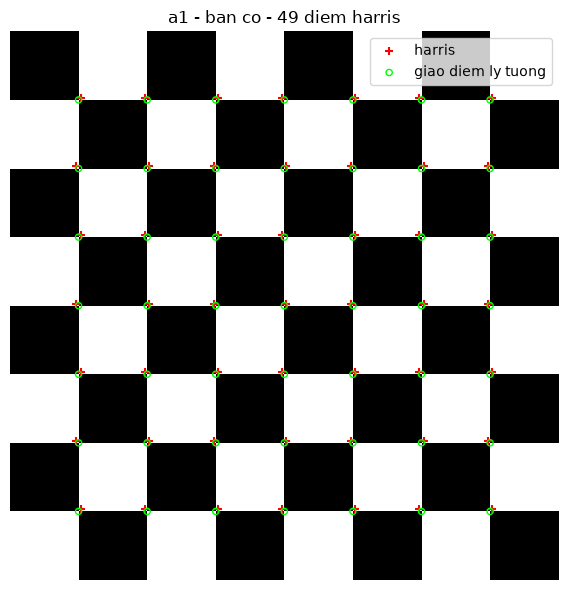

In [208]:

# a1 - ban co tong hop

cell_px = 16
so_o = 8

ban_co = np.zeros(
    (cell_px * so_o, cell_px * so_o),
    dtype=np.float64
)

for r in range(so_o):
    for c in range(so_o):
        if (r + c) % 2 == 1:
            ban_co[
                r * cell_px:(r + 1) * cell_px,
                c * cell_px:(c + 1) * cell_px
            ] = 255.0

# toa do 49 giao diem trong

giao_diem = np.array([
    (r * cell_px - 0.5, c * cell_px - 0.5)
    for r in range(1, so_o)
    for c in range(1, so_o)
], dtype=np.float64)


def danh_gia_ban_co(anh, ten):
    pts = harris_classic(
        anh,
        sigma_i=2.0,
        sigma_d=1.4,
        k=0.04,
        thresh_rel=0.01
    )

    if len(pts) > 0:
        d = np.linalg.norm(
            giao_diem[:, None, :] - pts[None, :, :2],
            axis=2
        )
        gan_nhat = d.min(axis=1)
        so_diem_gan = (d <= 1.0).sum(axis=1)
    else:
        gan_nhat = np.full(len(giao_diem), np.inf)
        so_diem_gan = np.zeros(len(giao_diem), dtype=int)

    hop_le = gan_nhat <= 1.0
    so_tim_thay = int(hop_le.sum())

    print(f"\n{ten}")
    print("kich thuoc anh:", anh.shape)
    print("so diem harris:", len(pts))
    print("so giao diem trong:", len(giao_diem))
    print("so giao diem trong 1 px:", so_tim_thay)
    print(
        "ti le giao diem trong 1 px:",
        round(so_tim_thay / len(giao_diem), 4)
    )
    print(
        "so giao diem co nhieu hon 1 diem harris:",
        int((so_diem_gan > 1).sum())
    )
    print(
        "sai so lon nhat (px):",
        round(float(gan_nhat.max()), 4)
    )
    print(
        "sai so trung binh (px):",
        round(float(gan_nhat.mean()), 4)
    )

    return pts


pts_255 = danh_gia_ban_co(
    ban_co,
    "ban co 0/255"
)

pts_01 = danh_gia_ban_co(
    ban_co / 255.0,
    "ban co 0/1"
)

pts_dao = danh_gia_ban_co(
    255.0 - ban_co,
    "ban co dao mau"
)

# hien thi ban co va cac diem

plt.figure(figsize=(6, 6))
plt.imshow(ban_co, cmap="gray")

if len(pts_255) > 0:
    plt.scatter(
        pts_255[:, 1],
        pts_255[:, 0],
        s=35,
        color="red",
        marker="+",
        label="harris"
    )

plt.scatter(
    giao_diem[:, 1],
    giao_diem[:, 0],
    s=20,
    facecolors="none",
    edgecolors="lime",
    marker="o",
    label="giao diem ly tuong"
)

plt.title(f"a1 - ban co - {len(pts_255)} diem harris")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Phát hiện đủ 49/49 giao điểm trong với sai số định vị lớn nhất 0.7071 px, nhỏ hơn 1 px. Ảnh 0/1 phát hiện thêm 24 điểm Harris so với ảnh 0/255
- Đạt/chưa đạt và lý do: Đạt yêu cầu vì tất cả giao điểm trong đều được phát hiện với sai số định vị không quá 1 px

### Kiểm chứng A2 - Xoay ảnh 30 độ

Báo số điểm và repeatability bằng phép biến đổi tọa độ đúng. Người phụ trách: Gấm.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**


- Công cụ: ChatGPT (OpenAI)
- Mục đích: Hỗ trợ viết và rà soát code kiểm chứng A1, A2, A4 dựa trên 6 hàm Harris đã có
- Prompt nguyên văn: "Từ cài đặt 6 hàm của thuật toán Harris đã được cung cấp, hãy xây dựng và rà soát kiểm chứng theo yêu cầu sau:  
  A1: Kiểm chứng các giao điểm trong và sai số định vị không quá 1 px  
  A2: Báo số điểm góc phát hiện được và tính repeatability bằng phép biến đổi tọa độ chính xác  
  A4: Sử dụng cv2.cornerHarris trong cell đối chiếu và báo số điểm khớp trong khoảng 2–3 px"
- Phần đã tự sửa và kiểm tra: Kiểm tra, chạy thử và đối chiếu kết quả thực nghiệm


Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

anh: home.jpg
kich thuoc anh: (384, 512)
goc xoay (do): 30.0
so diem anh goc: 332
so diem anh xoay: 290
so diem chieu nam trong anh xoay: 289
repeatability eps=1 px: 0.8235
repeatability eps=2 px: 0.8927
repeatability eps=3 px: 0.917
repeatability bang ma tran 3x3: 0.917
repeatability bang ham: 0.0
chenh lech hai cach tinh: 0.91695502


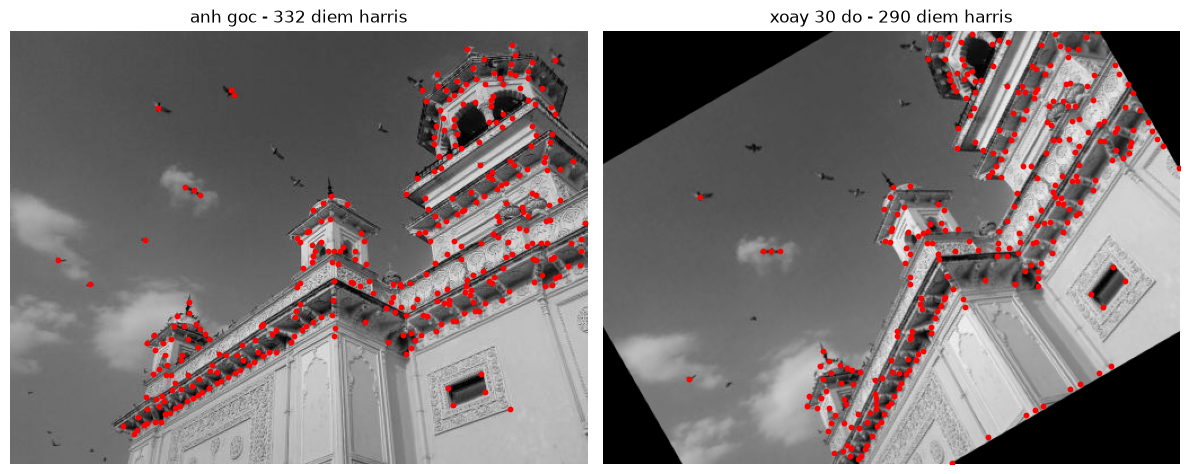

In [209]:

# a2 - xoay anh 30 do

import cv2

anh_goc = cv2.imread(
    str(IMAGES_DIR / "home.jpg"),
    cv2.IMREAD_GRAYSCALE
)

if anh_goc is None:
    raise FileNotFoundError("khong tim thay home.jpg")

anh_goc = anh_goc.astype(np.float64)
h, w = anh_goc.shape

goc = 30.0

M = cv2.getRotationMatrix2D(
    (w / 2, h / 2),
    goc,
    1.0
)

anh_xoay = cv2.warpAffine(
    anh_goc,
    M,
    (w, h)
)

H_xoay = np.vstack([
    M,
    [0.0, 0.0, 1.0]
])

pts_goc = harris_classic(anh_goc)
pts_xoay = harris_classic(anh_xoay)


def xoay_diem(p):
    # chuyen toa do row col sang x y

    x, y = p[1], p[0]

    x2 = M[0, 0] * x + M[0, 1] * y + M[0, 2]
    y2 = M[1, 0] * x + M[1, 1] * y + M[1, 2]

    return (y2, x2)


# tinh so diem chieu nam trong anh xoay

if len(pts_goc) > 0:
    chieu = np.array(
        [xoay_diem(p) for p in pts_goc[:, :2]],
        dtype=np.float64
    ).reshape(-1, 2)
else:
    chieu = np.empty((0, 2), dtype=np.float64)

trong_anh = (
    np.isfinite(chieu).all(axis=1) &
    (chieu[:, 0] >= 0) &
    (chieu[:, 0] < h) &
    (chieu[:, 1] >= 0) &
    (chieu[:, 1] < w)
)

rep_H = repeatability(
    pts_goc,
    pts_xoay,
    H_xoay,
    anh_xoay.shape,
    eps=3.0
)

rep_ham = repeatability(
    pts_goc,
    pts_xoay,
    xoay_diem,
    anh_xoay.shape,
    eps=3.0
)

print("anh:", "home.jpg")
print("kich thuoc anh:", anh_goc.shape)
print("goc xoay (do):", goc)
print("so diem anh goc:", len(pts_goc))
print("so diem anh xoay:", len(pts_xoay))
print(
    "so diem chieu nam trong anh xoay:",
    int(trong_anh.sum())
)

for e in (1.0, 2.0, 3.0):
    rep = repeatability(
        pts_goc,
        pts_xoay,
        H_xoay,
        anh_xoay.shape,
        eps=e
    )

    print(
        f"repeatability eps={e:.0f} px:",
        round(rep, 4)
    )

print(
    "repeatability bang ma tran 3x3:",
    round(rep_H, 4)
)
print(
    "repeatability bang ham:",
    round(rep_ham, 4)
)
print(
    "chenh lech hai cach tinh:",
    round(abs(rep_H - rep_ham), 8)
)

# hien thi anh goc va anh xoay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(anh_goc, cmap="gray")

if len(pts_goc) > 0:
    ax[0].scatter(
        pts_goc[:, 1],
        pts_goc[:, 0],
        s=10,
        color="red",
        marker="o"
    )

ax[0].set_title(f"anh goc - {len(pts_goc)} diem harris")

ax[1].imshow(anh_xoay, cmap="gray")

if len(pts_xoay) > 0:
    ax[1].scatter(
        pts_xoay[:, 1],
        pts_xoay[:, 0],
        s=10,
        color="red",
        marker="o"
    )

ax[1].set_title(f"xoay 30 do - {len(pts_xoay)} diem harris")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Phát hiện 332 điểm Harris trên ảnh gốc và 290 điểm trên ảnh xoay 30 độ. Repeatability bằng ma trận đạt 0.917 tại ngưỡng 3 px, nhưng kết quả bằng hàm biến đổi tọa độ là 0.0
- Đạt/chưa đạt và lý do: Chưa đạt đầy đủ vì hai cách biến đổi tọa độ cho kết quả không nhất quán, cần kiểm tra lại thứ tự tọa độ trong hàm biến đổi

### Kiểm chứng A4 - Đối chiếu OpenCV

Dùng cv2.cornerHarris trong cell đối chiếu; báo điểm khớp trong 2-3 px. Người phụ trách: Gấm.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**


- Công cụ: ChatGPT (OpenAI)
- Mục đích: Hỗ trợ viết và rà soát code kiểm chứng A1, A2, A4 dựa trên 6 hàm Harris đã có
- Prompt nguyên văn: "Từ cài đặt 6 hàm của thuật toán Harris đã được cung cấp, hãy xây dựng và rà soát kiểm chứng theo yêu cầu sau:  
  A1: Kiểm chứng các giao điểm trong và sai số định vị không quá 1 px  
  A2: Báo số điểm góc phát hiện được và tính repeatability bằng phép biến đổi tọa độ chính xác  
  A4: Sử dụng cv2.cornerHarris trong cell đối chiếu và báo số điểm khớp trong khoảng 2–3 px"
- Phần đã tự sửa và kiểm tra: Kiểm tra, chạy thử và đối chiếu kết quả thực nghiệm


Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

anh: home.jpg
kich thuoc anh: (384, 512)
so diem harris cua nhom: 332
so diem harris opencv: 854

nguong 2 px
so diem nhom khop opencv: 244
ti le diem nhom khop opencv: 0.7349
so diem opencv khop nhom: 260
ti le diem opencv khop nhom: 0.3044

nguong 3 px
so diem nhom khop opencv: 299
ti le diem nhom khop opencv: 0.9006
so diem opencv khop nhom: 361
ti le diem opencv khop nhom: 0.4227

top 100 diem manh nhat
so diem nhom: 100
so diem opencv: 100
so diem khop trong 3 px: 48
ti le khop trong 3 px: 0.48


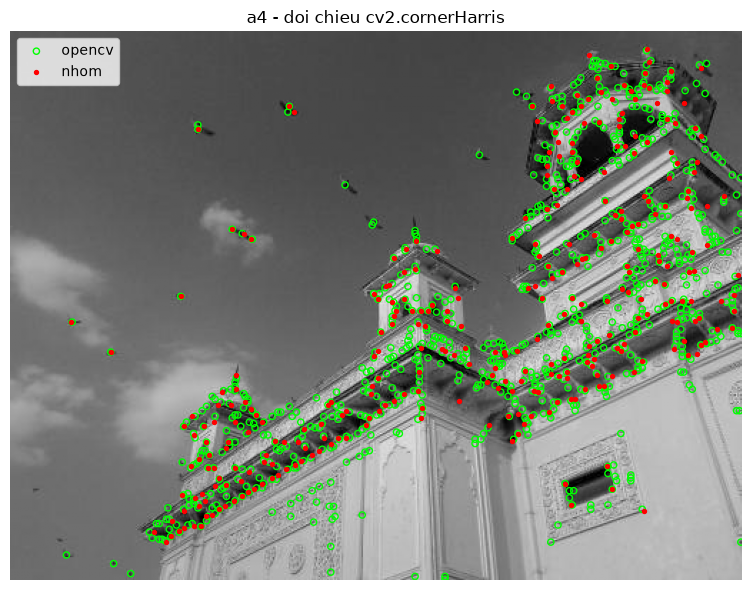

In [210]:

# a4 - doi chieu voi opencv

import cv2

anh = cv2.imread(
    str(IMAGES_DIR / "home.jpg"),
    cv2.IMREAD_GRAYSCALE
)

if anh is None:
    raise FileNotFoundError("khong tim thay home.jpg")

anh = anh.astype(np.float64)

pts_ta = harris_classic(
    anh,
    sigma_i=2.0,
    sigma_d=1.4,
    k=0.04,
    thresh_rel=0.01
)

# tinh dap ung harris bang opencv

R_cv = cv2.cornerHarris(
    anh.astype(np.float32),
    blockSize=5,
    ksize=3,
    k=0.04
).astype(np.float64)

max_cv = float(np.max(R_cv))

if max_cv > 0:
    mask_cv = nms_2d(R_cv, window=3)
    mask_cv &= np.isfinite(R_cv)
    mask_cv &= R_cv > 0.01 * max_cv
else:
    mask_cv = np.zeros(R_cv.shape, dtype=bool)

pts_cv = np.argwhere(mask_cv).astype(np.float64)

# tinh khoang cach giua hai tap diem

if len(pts_ta) > 0 and len(pts_cv) > 0:
    d = np.linalg.norm(
        pts_ta[:, None, :2] - pts_cv[None, :, :],
        axis=2
    )

    gan_ta = d.min(axis=1)
    gan_cv = d.min(axis=0)
else:
    gan_ta = np.full(len(pts_ta), np.inf)
    gan_cv = np.full(len(pts_cv), np.inf)

print("anh:", "home.jpg")
print("kich thuoc anh:", anh.shape)
print("so diem harris cua nhom:", len(pts_ta))
print("so diem harris opencv:", len(pts_cv))

for e in (2.0, 3.0):
    so_khop_ta = int((gan_ta <= e).sum())
    so_khop_cv = int((gan_cv <= e).sum())

    ti_le_ta = (
        so_khop_ta / len(pts_ta)
        if len(pts_ta) > 0 else 0.0
    )

    ti_le_cv = (
        so_khop_cv / len(pts_cv)
        if len(pts_cv) > 0 else 0.0
    )

    print(f"\nnguong {e:.0f} px")
    print("so diem nhom khop opencv:", so_khop_ta)
    print("ti le diem nhom khop opencv:", round(ti_le_ta, 4))
    print("so diem opencv khop nhom:", so_khop_cv)
    print("ti le diem opencv khop nhom:", round(ti_le_cv, 4))

# doi chieu 100 diem manh nhat

top_ta = pts_ta[:100, :2]

responses_cv = R_cv[mask_cv]
order_cv = np.argsort(-responses_cv, kind="stable")
top_cv = pts_cv[order_cv[:100]]

if len(top_ta) > 0 and len(top_cv) > 0:
    d_top = np.linalg.norm(
        top_ta[:, None, :] - top_cv[None, :, :],
        axis=2
    )

    gan_top = d_top.min(axis=1)
    so_khop_top = int((gan_top <= 3.0).sum())
    ti_le_top = float((gan_top <= 3.0).mean())
else:
    so_khop_top = 0
    ti_le_top = 0.0

print("\ntop 100 diem manh nhat")
print("so diem nhom:", len(top_ta))
print("so diem opencv:", len(top_cv))
print("so diem khop trong 3 px:", so_khop_top)
print("ti le khop trong 3 px:", round(ti_le_top, 4))

# hien thi ket qua doi chieu

plt.figure(figsize=(8, 6))
plt.imshow(anh, cmap="gray")

if len(pts_cv) > 0:
    plt.scatter(
        pts_cv[:, 1],
        pts_cv[:, 0],
        s=20,
        facecolors="none",
        edgecolors="lime",
        marker="o",
        label="opencv"
    )

if len(pts_ta) > 0:
    plt.scatter(
        pts_ta[:, 1],
        pts_ta[:, 0],
        s=8,
        color="red",
        marker="o",
        label="nhom"
    )

plt.title("a4 - doi chieu cv2.cornerHarris")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Hàm Harris của nhóm phát hiện 332 điểm, OpenCV phát hiện 854 điểm. Tỷ lệ điểm của nhóm khớp với OpenCV đạt 73.49% trong 2 px và 90.06% trong 3 px
- Đạt/chưa đạt và lý do: Đạt yêu cầu đối chiếu vì đã sử dụng cv2.cornerHarris và thống kê được tỷ lệ điểm khớp trong 2–3 px. Kết quả hai phương pháp có sự khác biệt về số lượng điểm phát hiện

## Thí nghiệm - Rà số đo và điều kiện so sánh của ba cặp

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



## Bàn giao cho nhóm trưởng

- [ ] Đúng giao diện hàm và quy ước tọa độ.
- [ ] Restart & Run All chạy được, đã lưu output.
- [ ] Ảnh cần dùng có trong images/ tại gốc repo; dùng IMAGES_DIR để đọc ảnh.
- [ ] Kiểm chứng và thí nghiệm có số đo thực tế.
- [ ] Cell thí nghiệm có dùng AI ghi đúng prompt ngay phía trên.
- [ ] Đã mở Pull Request và ghi nguồn các hàm dùng chung.